# Exercício 1 - caps 2 e 3

**Discente:** Raphael Ramos da Silva

Comparar, no mínimo, 3 otimizadores para a função de Rosenbrock.

- Usar implementações dos capítulos 2 e 3.
- Entregar um notebook com os resultados e análises.
- Pode ser implementado em MatLab ou Python.

## Implementações

Defino os seguintes métodos de suporte para minimizar a função de Rosenbrock

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from mpl_toolkits.mplot3d import Axes3D

def rosen_fn(w1, w2):
  """Computes the Rosenbrock function value."""
  return 100 * (w2 - w1**2)**2 + (1 - w1)**2

def grad_rosen_fn(w1, w2):
  """Computes the gradient vector of the Rosenbrock function."""
  g = np.array([-400 * w1 * (w2 - w1**2) - 2 * (1 - w1), 200 * (w2 - w1**2)], dtype="float32")
  return g

def hessian_rosen_fn(w1, w2):
  """Computes the Hessian matrix of the Rosenbrock function."""
  H = [[1200 * w1**2 - 400 * w2 + 2, -400 * w1],
       [-400 * w1, 200]]
  return np.array(H, dtype="float32")

Para visualização e entendimento da função, implementa-se também rotinas para fazer o seu plot 3D e 2D

In [ ]:
def plot_rosenbrock_3d(title, w1_range=(-2, 2), w2_range=(-2, 2)):
    """Plots the 3D surface of the Rosenbrock function."""
    w1_vals = np.linspace(w1_range[0], w1_range[1], 100)
    w2_vals = np.linspace(w2_range[0], w2_range[1], 100)
    W1, W2 = np.meshgrid(w1_vals, w2_vals)
    Z = rosen_fn(W1, W2)

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")

    # Superfície 3D
    ax.plot_surface(W1, W2, Z, cmap="viridis", edgecolor="none", alpha=0.8)

    # Plot do Mínimo Global exato (1, 1, 0)
    ax.scatter(
        1.0,
        1.0,
        rosen_fn(1.0, 1.0),
        color="red",
        marker="o",
        s=100,
        edgecolor="black",
        label="Mínimo Global (1, 1, 0)",
    )

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("w1")
    ax.set_ylabel("w2")
    ax.set_zlabel("f(w1, w2)")
    ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()


def plot_rosenbrock_2d(
    w_history: list,
    title,
    w1_range=(-2.0, 2.0),
    w2_range=(-2.0, 2.0),
):
    """Plots the 2D Rosenbrock function contour and the optimization path."""
    w_history = np.array(w_history)

    w1_vals = np.linspace(w1_range[0], w1_range[1], 300)
    w2_vals = np.linspace(w2_range[0], w2_range[1], 300)
    W1, W2 = np.meshgrid(w1_vals, w2_vals)
    Z = rosen_fn(W1, W2)

    fig, ax = plt.subplots(figsize=(7, 6))

    # Níveis logarítmicos
    levels = np.logspace(-0.5, 3.5, 35)

    cs = ax.contourf(
        W1, W2, Z, levels=levels, cmap="viridis", norm=LogNorm(), extend="both"
    )

    cbar = fig.colorbar(cs, ax=ax, format="%2.1f")
    cbar.set_label("Valor da Função de Rosenbrock (Escala Log)")

    ax.contour(
        W1, W2, Z, levels=levels[::3], colors="white", linewidths=0.5, alpha=0.6
    )

    if len(w_history) > 0:
        # Caminho da otimização
        ax.plot(
            w_history[:, 0],
            w_history[:, 1],
            "-o",
            color="white",
            linewidth=1.5,
            markersize=3,
            label="Caminho de Iterações",
        )

        # Ponto Inicial
        ax.plot(
            w_history[0, 0],
            w_history[0, 1],
            "o",
            color="lime",
            markeredgecolor="black",
            markersize=7,
            label="Ponto Inicial",
        )

        # Ponto Final
        ax.plot(
            w_history[-1, 0],
            w_history[-1, 1],
            "o",
            color="red",
            markeredgecolor="black",
            markersize=7,
            label="Ponto Final",
        )

    # Plot correto do Mínimo Global em (1.0, 1.0)
    ax.plot(
        1.0,
        1.0,
        "*",
        color="gold",
        markeredgecolor="black",
        markersize=12,
        label="Mínimo Global (1, 1)",
    )

    ax.set_title(title, fontweight="bold", fontsize=11)
    ax.set_xlabel("w1", fontsize=10)
    ax.set_ylabel("w2", fontsize=10)
    ax.set_xlim(w1_range[0], w1_range[1])
    ax.set_ylim(w2_range[0], w2_range[1])

    # Legenda ajustada para fundo claro/escuro
    ax.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.8)

    plt.tight_layout()
    plt.show()

Na subseção seguir estão as implementações dos otimizadores escolhidos para fazer este exercício: o Método de Newton, Gradiente Adaptativo (Adagrad) e Estimativa Adaptativa de Momentos (Adam)

### Método de Newton

$$
\textbf{w}^{(k)} = \textbf{w}^{(k+1)} - \textbf{H}^{-1}\textbf{g}
$$

onde:
* $\mathbf{g} = \nabla f(\mathbf{w}^{(k)}) \in \mathbb{R}^n$ é o **vetor gradiente** (vetor das primeiras derivadas parciais da função de custo no ponto $\mathbf{w}^{(k)}$).
* $\mathbf{H} = \nabla^2 f(\mathbf{w}^{(k)}) \in \mathbb{R}^{n \times n}$ é a **matriz Hessiana** (matriz das segundas derivadas parciais, que fornece a informação da curvatura local).
* $\mathbf{H}^{-1}\mathbf{g}$ representa o **passo de Newton**, que escala a direção de descida ajustando-a de acordo com a curvatura da superfície.

In [ ]:
def newton_method_optimizer(w10, w20, iterations):
  """Performs optimization using Newton's method."""
  w = np.array([w10, w20], dtype="float32")
  w_history = [w.copy()]

  for k in range(iterations):
    g = grad_rosen_fn(w[0], w[1])
    H = hessian_rosen_fn(w[0], w[1])
    delta_w = np.linalg.solve(H, g)
    w = w - delta_w
    w_history.append(w.copy())

  return w_history

### Adagrad

O Gradiente adaptativo (Adagrad) é definido iterativamente por

$$w_i^{(k+1)} = w_i^{(k)} - \frac{\alpha}{\left( \sum_{k'=1}^{k} (g_i^{(k)})^2 + \eta \right)^{1/2}} \frac{\partial \epsilon^{(k)}}{\partial w_i}$$

onde:
* $w_i^{(k+1)}$ é o **novo valor do peso** da componente $i$ para a próxima iteração $(k+1)$.
* $w_i^{(k)}$ é o **valor atual do peso** da componente $i$ na iteração $k$.
* $\alpha$ é a **taxa de aprendizagem global** (*learning rate*), que define o tamanho do passo.
* $g_i^{(k)}=\frac{\partial \epsilon^{(k)}}{\partial w_i}$ é o **gradiente da função de custo** ($\epsilon$) em relação ao peso $w_i$ na iteração $k$.
* $\left( \sum_{k'=1}^{k} (g_i^{(k')})^2 + \eta \right)^{1/2}$ representa a **raiz quadrada da soma acumulada dos quadrados dos gradientes** passados para a componente $i$, ajustando adaptativamente o aprendizado por peso e somada ao termo de suavização $\eta$ (para evitar divisão por zero).

A ideia principal é: em vez de usar uma taxa de aprendizado única para todas as direções ou calclar a matriz Hessiana, o Adagrad aplica um passo adaptativo para cada componente de $\textbf{w}$.

Com muitas iterações, o acúmulo dos gradientes faz com que o denominador cresça demais, levando o segundo termo do lado direito da equação a zero. Por causa disso, a convergência **estagna** porque o $w_i^{(k+1)}$ (próximo passo) fica cada vez mais próximo de $w_i^{(k)}$ (passo anterior)

In [ ]:
def adagrad_optimizer(w10, w20, iterations, alpha=1e-2, eta=1e-8):
  """Performs optimization using the Adagrad method."""
  w = np.array([w10, w20], dtype="float32")
  w_history = [w.copy()]
  s = np.zeros(2, dtype="float32")

  for it in range(iterations):
    g = grad_rosen_fn(w[0], w[1])
    s += g**2
    w = w - (alpha / (np.sqrt(s) + eta)) * g
    w_history.append(w.copy())

  return w_history

### Adam

A Estimativa Adaptativa de Momentos (Adam) para iterativamente minimizar uma função objetivo $f$ com uma entrada $\text{w}=(w_1, w_2, \dots, w_n)$ é dada conforme as seguintes etapas

Primeiro, calculamos os momentos

$$m_i^{(k)} = \beta_1 \cdot m_i^{(k-1)} + (1 - \beta_1) \cdot g_i^{(k)}$$
$$s_i^{(k)} = \beta_2 \cdot s_i^{(k-1)} + (1 - \beta_2) \cdot \left(g_i^{(k)}\right)^2$$

Depois, corrigimos o viés

$$\widehat{m}_i^{(k)} = \frac{m_i^{(k)}}{1 - \beta_1^k}$$
$$\widehat{s}_i^{(k)} = \frac{s_i^{(k)}}{1 - \beta_2^k}$$

Assim, a equação final de atualização dos parâmetros fica:

$$w_i^{(k+1)} = w_i^{(k)} - \frac{\alpha}{\sqrt{\widehat{s}_i^{(k)}} + \lambda} \cdot \widehat{m}_i^{(k)}$$

onde:
* $w_i^{(k+1)}$ é o **novo valor do peso** da componente $i$ para a próxima iteração $(k+1)$.
* $w_i^{(k)}$ é o **valor atual do peso** da componente $i$ na iteração $k$.
* $\alpha$ é a **taxa de aprendizagem global** (*learning rate*), que define o tamanho do passo.
* $\widehat{m}_i^{(k)} = \frac{m_i^{(k)}}{1 - \beta_1^k}$ é a **estimativa corrigida do primeiro momento** (média móvel exponencial dos gradientes com correção de vício inicial).
* $\widehat{s}_i^{(k)} = \frac{s_i^{(k)}}{1 - \beta_2^k}$ é a **estimativa corrigida do segundo momento** (média móvel exponencial dos quadrados dos gradientes com correção de vício inicial).
* $\lambda$ (ou $\epsilon$) é a **constante de suavização** (geralmente $10^{-8}$) para evitar a divisão por zero.

In [ ]:
def adam_optimizer(w10, w20, iterations, alpha, beta1, beta2, lam=1e-8):
  """
  Performs optimization using the Adam method.
  """
  # Notas:
  #   1. alpha: Concede liberdade para explorar sem estagnar o progresso.
  #   2. beta1: Controla as oscilações e suaviza a direção do movimento.
  #   3. beta2: Coeficiente de decaimento do segundo momento
  #     - Baixo: descarta o histórico rapidamente, reagindo mais aos gradientes recentes e, portanto, explorando minimos locais
  #     - Alto: o histórico antigo domina a média móvel, ignorando picos isolados de gradiente no passo atual.
  w = np.array([w10, w20], dtype=np.float64)
  w_history = [w.copy()]
  m = np.zeros(2, dtype=np.float64)
  s = np.zeros(2, dtype=np.float64)

  for it in range(1, iterations + 1):
    g = grad_rosen_fn(w[0], w[1])
    m = beta1 * m + (1 - beta1) * g
    s = beta2 * s + (1 - beta2) * (g**2)
    mh = m / (1 - beta1**it)
    sh = s / (1 - beta2**it)
    w = w - alpha * mh / (np.sqrt(sh) + lam)
    w_history.append(w.copy())

  return w_history

### Visualização dos resultados

Afim de visualizar os resultados, define-se também uma rotina para exibir o ponto $\textbf{w}^{(i)}$ que minimizou $y=f(w_1, w_2)$ entre todas as iterações, e o caminho de otimização no mapa de contornos

In [ ]:
def display_results(w_history, title, w1_range, w2_range):
    """Displays the 2D Rosenbrock function contour and the optimization path."""
    # Avalia a função ao longo do histórico para encontrar a melhor iteração
    costs = [rosen_fn(w1=w[0], w2=w[1]) for w in w_history]
    min_it = np.argmin(costs)
    best_w = w_history[min_it]

    # Exibição dos resultados no terminal
    print("=" * 40)
    print(f"  {title.upper()}")
    print("=" * 40)
    print(f" Solução ótima (w) : {best_w}")
    print(f" Menor Custo f(w)   : {costs[min_it]:.8f}")
    print(f" Iteração que levou ao Menor Custo : {min_it}")
    print("=" * 40 + "\n")

    # Renderiza o gráfico do caminho da otimização
    plot_rosenbrock_2d(w_history, title, w1_range, w2_range)

def opt_rosen_newton(w0: list, its: int, w1_range=(0.4, 1.25), w2_range=(0.25,2.0)):
  title = f"Método de Newton - Rosenbrock (its={its}, $w_1^{{(0)}}={w0[0]:.2f}, w_2^{{(0)}}={w0[1]:.2f}$)"
  w_history = newton_method_optimizer(w0[0], w0[1], its)
  display_results(w_history, title, w1_range, w2_range)

def opt_rosen_adagrad(w0: list, alpha, its: int, w1_range=(0.4, 1.25), w2_range=(0.25,2.0)):
  title = f"Adagrad - Rosenbrock (a={alpha}, its={its}, $w_1^{{(0)}}={w0[0]:.2f}$, $w_2^{{(0)}}={w0[1]:.2f}$)"
  w_history = adagrad_optimizer(w0[0], w0[1], its, alpha)
  display_results(w_history, title, w1_range, w2_range)

def opt_rosen_adam(w0: list, alpha, beta1, beta2, its: int, w1_range=(0.4, 1.25), w2_range=(0.25,2.0)):
  title = f"Adam - Rosenbrock (a={alpha}, $b_1={beta1}$, $b_2={beta2}$, $its={its}$, $w_1^{{(0)}}={w0[0]:.2f}$, $w_2^{{(0)}}={w0[1]:.2f})$)"
  w_history = adam_optimizer(w0[0], w0[1], its, alpha, beta1, beta2)
  display_results(w_history, title, w1_range, w2_range)

## Resultados e Análises

### Comentários da função objetivo

A seguir estão apresentados os plots do mapa de contornos e do grid 3D da função de Rosenbrock.

O mínimo global da função de Rosenbrock está localizado em $\textbf{w}=(1.0,1.0)$.

Na vizinhança desse mínimo, existe um vale plano (curvatura quase nula) com poucas variações de gradiente. As paredes que levam a esse vale são íngremes e inclinadas, com gradientes extremamente altos (observe como as cores no plot 2D, que representam a intensidade de $f$, variam acentuadamente quando descemos nesse vale).

Essas condições são propícias para os otimizadores serem "puxados" para o vale e navegarem nele até encontrar a solução.


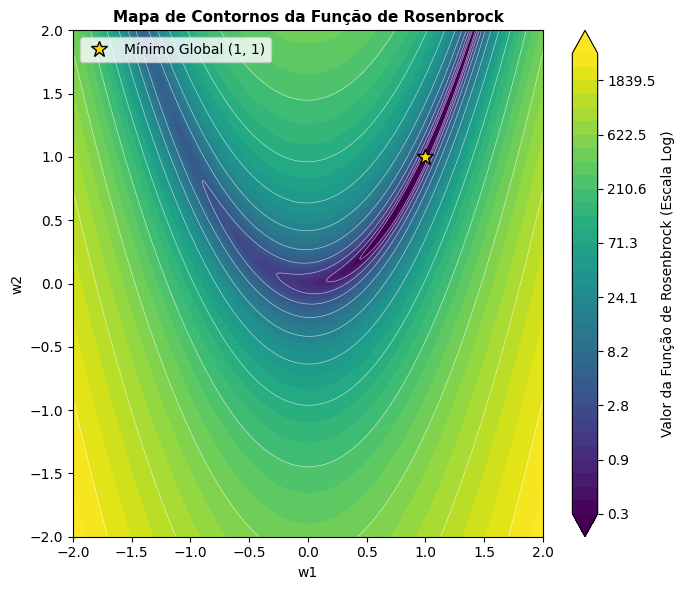

In [ ]:
plot_rosenbrock_2d([], "Mapa de Contornos da Função de Rosenbrock", w1_range=(-2, 2), w2_range=(-2, 2))

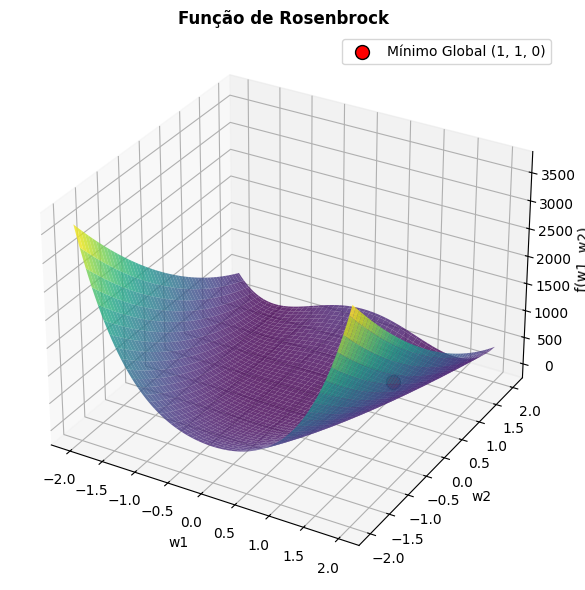

In [ ]:
plot_rosenbrock_3d("Função de Rosenbrock", w1_range=(-2, 2), w2_range=(-2, 2))

### Método de Newton

Escolhendo um ponto próximo ao vale $\textbf{w}=[0.6, 0.4]$, o método navega suavemente pelo fundo do vale e atinge exatamente o mínimo global, convergindo quase que de forma direta. Isso ocorre porque o passo de Newton $\textbf{H}^{-1}g$ ajusta tanto a direção quanto a magnitude dos deslocamentos aplicados a $\textbf{w}^{(k)}$ de forma adaptativa.

  MÉTODO DE NEWTON - ROSENBROCK (ITS=10, $W_1^{(0)}=0.60, W_2^{(0)}=0.40$)
 Solução ótima (w) : [1. 1.]
 Menor Custo f(w)   : 0.00000000
 Iteração que levou ao Menor Custo : 7



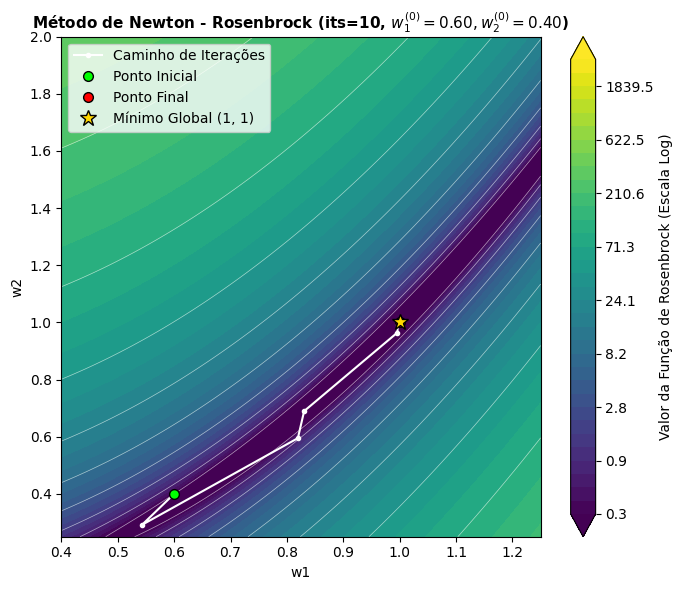

In [ ]:
opt_rosen_newton([0.6, 0.4], its=10)

Executando com um ponto posicionado nas paredes íngremes  $\textbf{w}=[-2, 2]$, afastado do mínimo global, observamos em um primeiro momento o método dar saltos longos para a borda inferior do mapa (próximo de $\textbf{w}=[1, -7.8]$), mas consegue calcular a nova curvatura para projetar o caminho de volta para a solução ótima.

  MÉTODO DE NEWTON - ROSENBROCK (ITS=10, $W_1^{(0)}=-2.00, W_2^{(0)}=2.00$)
 Solução ótima (w) : [1. 1.]
 Menor Custo f(w)   : 0.00000000
 Iteração que levou ao Menor Custo : 6



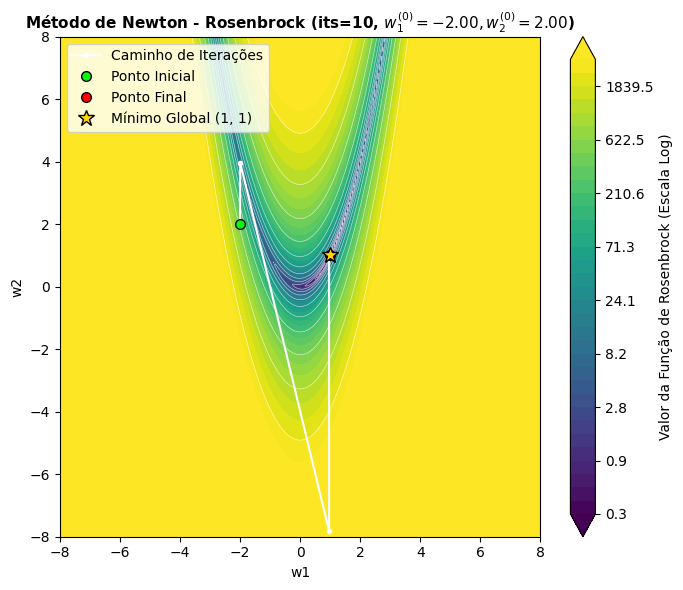

In [ ]:
opt_rosen_newton([-2, 2], 10, w1_range=(-8, 8), w2_range=(-8, 8))

In [ ]:
# imprimir exatamente quais pontos foram visitados
w_history = newton_method_optimizer(-2, 2, 10)
print(
  " -> ".join([f"({w[0]:.2f}, {w[1]:.2f})" for w in w_history])
)

(-2.00, 2.00) -> (-1.99, 3.97) -> (0.97, -7.82) -> (0.97, 0.93) -> (1.00, 1.00) -> (1.00, 1.00) -> (1.00, 1.00) -> (1.00, 1.00) -> (1.00, 1.00) -> (1.00, 1.00) -> (1.00, 1.00)


### Adagrad

Escolhendo um número de iterações baixo ($\text{its}=10$), mesmo próximo do mínimo $\textbf{w}=(0.6, 0.4)$, a componente $g_{\perp}$ amortece saltos acentuados na parede íngreme que leva ao vale. Por causa disso, o otimizador tende a permanecer distante do mínimo global por mais tempo. Isso é visível na figura a seguir: na última iteração, o otimizador parou em algo próximo de $(0.63,0.37)$

  ADAGRAD - ROSENBROCK (A=0.01, ITS=10, $W_1^{(0)}=0.60$, $W_2^{(0)}=0.40$)
 Solução ótima (w) : [0.6210808  0.38417006]
 Menor Custo f(w)   : 0.14382666
 Iteração que levou ao Menor Custo : 10



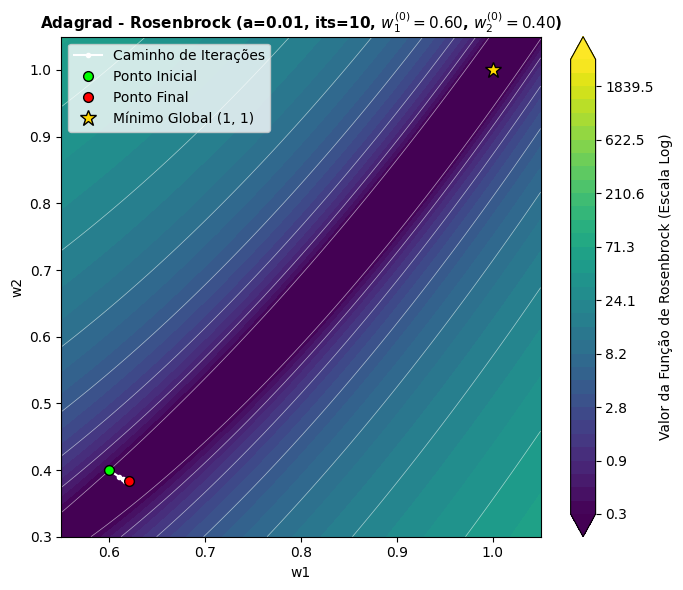

In [ ]:
opt_rosen_adagrad([0.6, 0.4], alpha=0.01, its=10, w1_range=(0.55, 1.05), w2_range=(0.3, 1.05))

Com a mesma configuração do experimento anterior (com o mesmo ponto inicial e $\alpha=0,01$), mas permitindo mais iterações ($\text{its}=3\times 10^{4}$), em resposta ao amortecimento da componente $g_{\perp}$ do gradiente, o Adagrad, da iteração 28048 em diante, estagna no ponto $\textbf{w}=[0.9999423, 0.9998844]$, o qual é muito próximo da vizinhança do mínimo global.

  ADAGRAD - ROSENBROCK (A=0.01, ITS=30000, $W_1^{(0)}=0.60$, $W_2^{(0)}=0.40$)
 Solução ótima (w) : [0.9999423 0.9998844]
 Menor Custo f(w)   : 0.00000000
 Iteração que levou ao Menor Custo : 28048



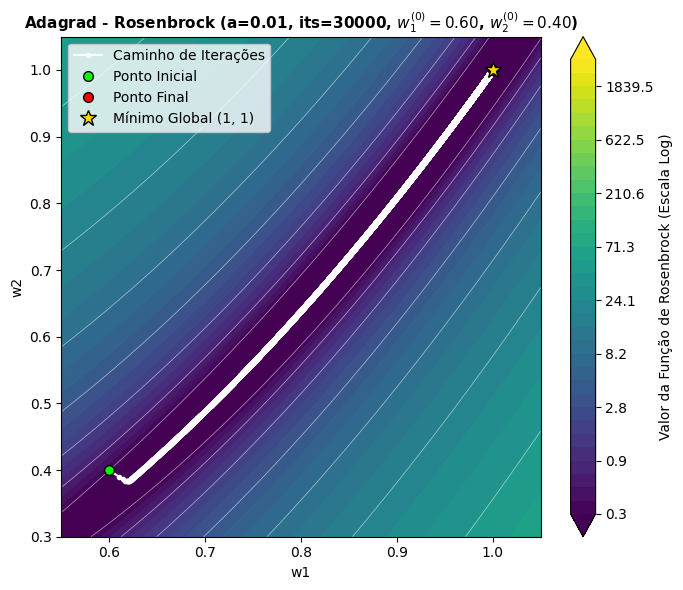

In [ ]:
opt_rosen_adagrad([0.6, 0.4], alpha=0.01, its=30000, w1_range=(0.55, 1.05), w2_range=(0.3, 1.05))

Aproveitando o número máximo de iterações do experimento anterior, o experimento a seguir mostra que conseguimos diminuir consideravelmente a quantidade de iterações até a convergência para 10132 iterações, ao aumentar o passo constante para $\alpha=0,05$. Isso ocorre porque um $\alpha$ maior consegue controlar a "frenagem" causada pelo acúmulo dos gradientes, forçando avanços mais "longos" no vale, causado pela amplificação na componente $g_{\parallel}$.

  ADAGRAD - ROSENBROCK (A=0.05, ITS=30000, $W_1^{(0)}=0.60$, $W_2^{(0)}=0.40$)
 Solução ótima (w) : [0.99998796 0.9999753 ]
 Menor Custo f(w)   : 0.00000000
 Iteração que levou ao Menor Custo : 10132



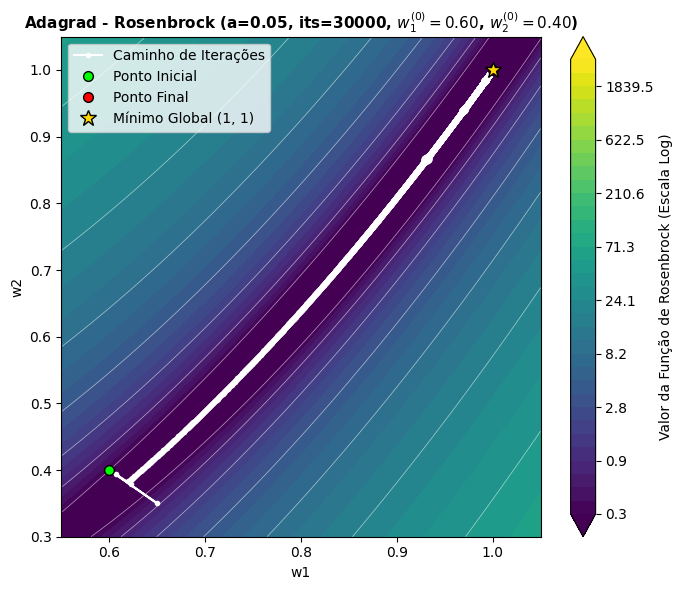

In [ ]:
opt_rosen_adagrad([0.6, 0.4], alpha=0.05, its=30000, w1_range=(0.55, 1.05), w2_range=(0.3, 1.05))

### Adam

#### Configuração padrão

Com as configurações padrão para o Adam ($\alpha=0.1, \beta_1=0.9, \beta_2=0.999$) e um ponto inicial próximo ao vale ($\mathbf{w}^{(0)}=[0.6, 0.4]$), o otimizador toca um ponto ótimo, em relação ao histórico de iterações, na iteração 838, contudo, se distancia do mínimo global e acaba não convergindo.

Um ponto importante a observar neste primeiro experimento é que, nas primeiras iterações, o método Adam "flutua" nas paredes íngremes da função dentro do quadrado $Q=[0.3, 0.7]\times[0.3,0.45]$. Esse comportamento ocorre porque os valores iniciais dos momentos ainda são baixos ($m^{(0)}=0, \sigma^{2(0)}=0$), fazendo com que o primeiro momento ainda não direcione totalmente o fluxo ao longo da componente do vale ($g_{\parallel}$) e o segundo momento não estabilize por completo o tamanho dos passos.

Posteriormente, à medida que o histórico dos gradientes se acumula nas iterações seguintes, o método torna-se mais direcionado, percorrendo a calha de forma contínua em direção ao mínimo global em $\mathbf{w}^*=(1.0, 1.0)$. Contudo acaba por oscilar novamente na vizinhança do mínimo, e, nas últimas iterações, se afastar dele.

  ADAM - ROSENBROCK (A=0.1, $B_1=0.9$, $B_2=0.999$, $ITS=1000$, $W_1^{(0)}=0.60$, $W_2^{(0)}=0.40)$)
 Solução ótima (w) : [0.9999953 0.9999907]
 Menor Custo f(w)   : 0.00000000
 Iteração que levou ao Menor Custo : 838



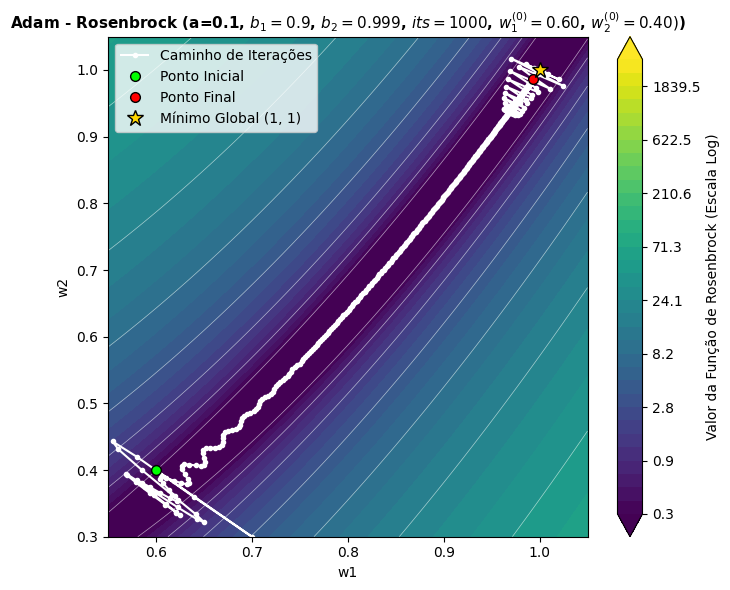

In [ ]:
opt_rosen_adam([0.6, 0.4], alpha=0.1, beta1=0.9, beta2=0.999, its=1000, w1_range=(0.55, 1.05), w2_range=(0.3, 1.05))

#### Diminuição do $\beta_1$

Aqui, diminui-se o $\beta_1$ para $0.5$. Por conta disso, o algoritmo dá menos peso às médias móveis dos gradientes passados. Assim, como é possível ver no *plot* a seguir, o otimizador reage mais rapidamente aos gradientes recentes, resultando em um caminho de otimização com mais oscilações.

  ADAM - ROSENBROCK (A=0.1, $B_1=0.5$, $B_2=0.999$, $ITS=1000$, $W_1^{(0)}=0.60$, $W_2^{(0)}=0.40)$)
 Solução ótima (w) : [0.89453439 0.79882731]
 Menor Custo f(w)   : 0.01130917
 Iteração que levou ao Menor Custo : 900



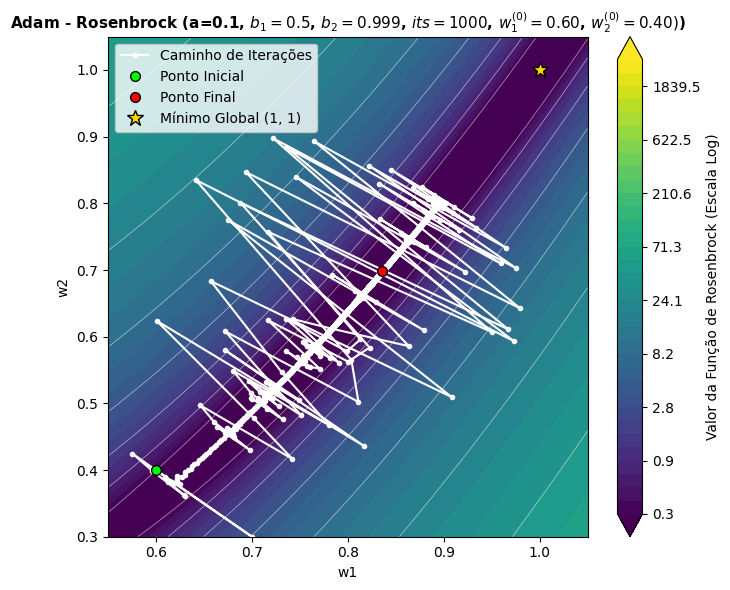

In [ ]:
opt_rosen_adam([0.6, 0.4], alpha=0.1, beta1=0.5, beta2=0.999, its=1000, w1_range=(0.55, 1.05), w2_range=(0.3, 1.05))

#### Diminuição do $\beta_2$

Diminuindo $\beta_2$ para $0.9$, o algoritmo atribui menos peso à média móvel dos gradientes quadrados. Isso significa que ele se torna mais sensível às variações nos gradientes recentes, o que pode levar a um comportamento mais errático ou a uma maior exploração da vizinhança do mínimo global. Neste experimento em específico, o otimizador apresentou ondulações ao caminhar pelo vale, justamente por tentar explorar mais a vizinhança em cada iteração. Apesar desse movimento oscilatório indesejado, esse comportamento pode ser útil em superfícies com muitos mínimos locais, pois permite explorar mais a função de custo.

  ADAM - ROSENBROCK (A=0.1, $B_1=0.9$, $B_2=0.9$, $ITS=2000$, $W_1^{(0)}=0.60$, $W_2^{(0)}=0.40)$)
 Solução ótima (w) : [0.99461887 0.98925013]
 Menor Custo f(w)   : 0.00002898
 Iteração que levou ao Menor Custo : 983



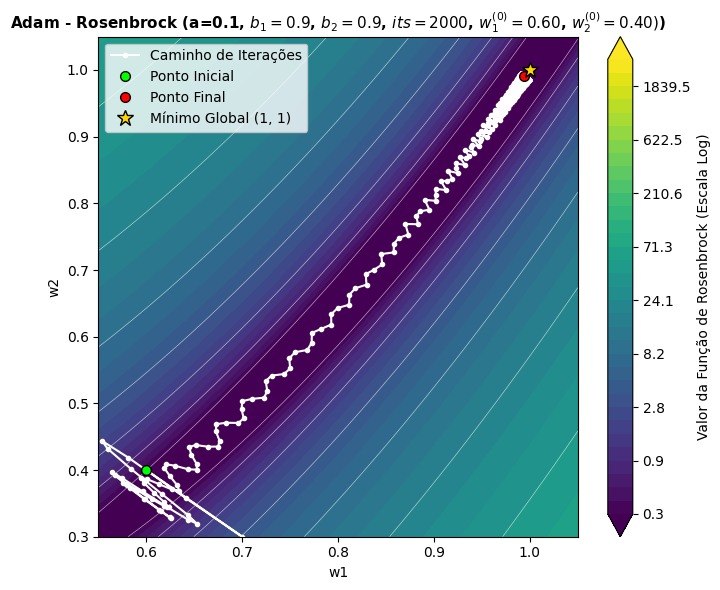

In [ ]:
opt_rosen_adam([0.6, 0.4], alpha=0.1, beta1=0.9, beta2=0.9, its=2000, w1_range=(0.55, 1.05), w2_range=(0.3, 1.05))

#### Aumento da Taxa de aprendizagem ($\alpha$)

Ao triplicar a taxa de aprendizado para $\alpha = 0.3$, o otimizador diverge.

Nota-se que um $\alpha$ elevado acelera o deslocamento ao longo da calha parabólica do vale. Contudo, ao se aproximar do mínimo global na vizinhança de $\mathbf{w}^* = (1.0, 1.0)$, a magnitude excessiva do passo faz com que o algoritmo "ultrapasse" (*overshoot*) a região de mínimo, projetando o ponto $\mathbf{w}^{(k)}$ para áreas de maior custo no lado oposto da bacia.

Observamos claramente esse comportamento de afastamento nos resultados abaixo: note como o otimizador se aproxima da vizinhança do mínimo global (direita do gráfico), e, de repente, se afasta para a direção do Ponto Inicial (esquerda do gráfico)

  ADAM - ROSENBROCK (A=0.3, $B_1=0.9$, $B_2=0.999$, $ITS=1000$, $W_1^{(0)}=0.60$, $W_2^{(0)}=0.40)$)
 Solução ótima (w) : [0.99999621 0.99999231]
 Menor Custo f(w)   : 0.00000000
 Iteração que levou ao Menor Custo : 954



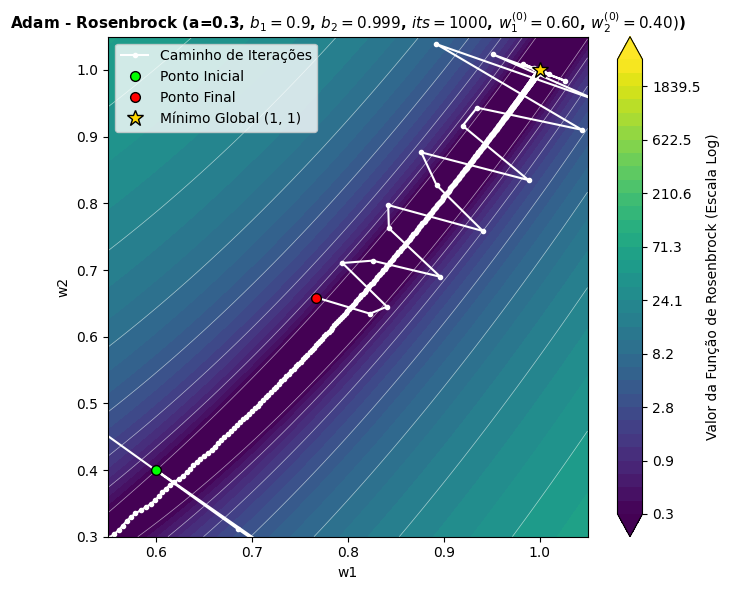

In [ ]:
opt_rosen_adam([0.6, 0.4], alpha=0.3, beta1=0.9, beta2=0.999, its=1000, w1_range=(0.55, 1.05), w2_range=(0.3, 1.05))

#### Diminuição da Taxa de aprendizagem ($\alpha$)

Com a diminuição da taxa de aprendizado ($\alpha$) para 0.001 e o aumento do número de iterações para 10000, o otimizador Adam converge para o mínimo global (1, 1) da função de Rosenbrock, atingindo um custo de 0.00000000 na iteração 7012. Embora o número de iterações para atingir a solução ótima seja maior em comparação com um $\alpha$ mais elevado, a trajetória é mais suave, evitando as oscilações observadas anteriormente. Isso demonstra que um $\alpha$ menor, embora mais lento, pode ser mais robusto para a convergência em problemas como este.

  ADAM - ROSENBROCK (A=0.001, $B_1=0.9$, $B_2=0.999$, $ITS=10000$, $W_1^{(0)}=0.60$, $W_2^{(0)}=0.40)$)
 Solução ótima (w) : [1. 1.]
 Menor Custo f(w)   : 0.00000000
 Iteração que levou ao Menor Custo : 7012



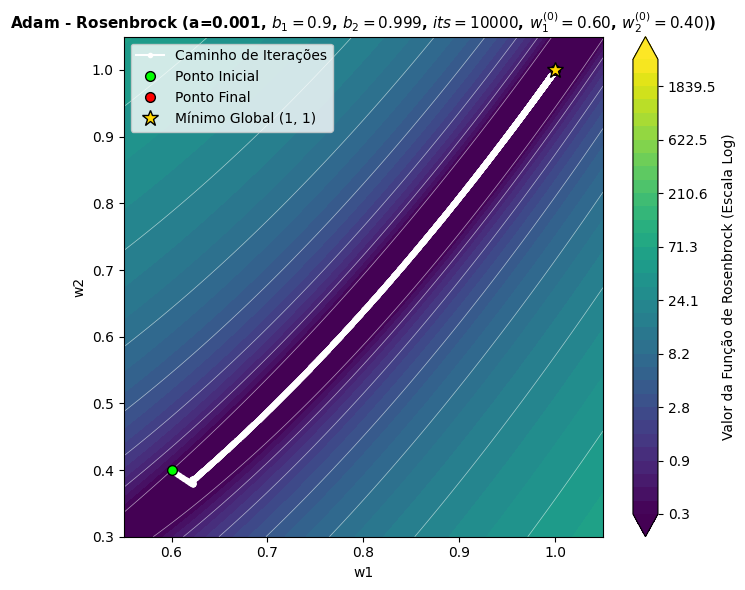

In [ ]:
opt_rosen_adam([0.6, 0.4], alpha=0.001, beta1=0.9, beta2=0.999, its=10000, w1_range=(0.55, 1.05), w2_range=(0.3, 1.05))